In [ ]:
# Healthcare Analytics Portfolio
# Project 1: Data Quality Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Healthcare Data Quality Analysis")
print("Libraries imported successfully.")

Healthcare Data Quality Analysis
Libraries imported successfully.


In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
# Load the healthcare dataset
import io

file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

# Verify the dataset
print("Dataset loaded successfully.")
print(f"File name: {file_name}")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

# Preview the first five records
df.head()

Dataset loaded successfully.
File name: fact_encounters_rows.csv
Number of rows: 100,000
Number of columns: 15


,encounter_id,patient_id,provider_id,date_id,diagnosis_id,insurance_type,location_id,length_of_stay,total_cost,medication_cost,claim_amount,er_visit,readmission_30_days,patient_satisfaction,outcome
0,E0000001,P05954,PR0427,"20,250,525.00",D005,Medicare,L003,0,"1,376.70",260.93,"1,337.61",0,0,4.20,Improved
1,E0000002,P15853,PR0190,"20,240,217.00",D007,Commercial,L006,8,"8,185.68",827.37,"8,718.21",1,0,4.10,Improved
2,E0000003,P17223,PR0348,"20,240,123.00",D001,Commercial,L003,2,"3,204.73",513.20,"2,256.70",0,0,4.70,Improved
3,E0000004,P03195,PR0254,"20,250,520.00",D002,Commercial,L006,2,"1,600.46",126.86,"1,090.12",0,0,4.10,Improved
4,E0000005,P11278,PR0240,"20,250,507.00",D010,Medicare,L003,1,"1,037.43",287.64,867.20,0,0,4.50,Improved


In [ ]:
# Reset the global number format to avoid confusing identifiers
pd.reset_option("display.float_format")

# Review the data types of each column
print("DATA TYPES")
display(df.dtypes.to_frame(name="Data Type"))

# Count missing values in each column
print("MISSING VALUES")
missing_values = df.isnull().sum().sort_values(ascending=False)
display(missing_values.to_frame(name="Missing Count"))

# Summarize the dataset structure
print(f"Total records: {len(df):,}")
print(f"Total columns: {len(df.columns)}")
print(f"Duplicate encounter IDs: {df['encounter_id'].duplicated().sum():,}")

DATA TYPES


,Data Type
encounter_id,object
patient_id,object
provider_id,object
date_id,float64
diagnosis_id,object
insurance_type,object
location_id,object
length_of_stay,int64
total_cost,float64
medication_cost,float64


MISSING VALUES


,Missing Count
patient_satisfaction,900
provider_id,250
date_id,15
patient_id,0
diagnosis_id,0
insurance_type,0
encounter_id,0
location_id,0
length_of_stay,0
medication_cost,0


Total records: 100,000
Total columns: 15
Duplicate encounter IDs: 0


In [ ]:
# Check for duplicate encounter identifiers
duplicate_count = df["encounter_id"].duplicated().sum()

print(f"Duplicate encounter IDs: {duplicate_count:,}")

# Inspect records with missing dates
missing_dates = df[df["date_id"].isna()]

print(f"\nRecords with missing dates: {len(missing_dates):,}")

display(
    missing_dates[
        ["encounter_id", "patient_id", "provider_id", "date_id"]
    ].head(10)
)

Duplicate encounter IDs: 0

Records with missing dates: 15


,encounter_id,patient_id,provider_id,date_id
9,E0000010,P17159,PR0340,NaN
2168,E0002169,P17618,PR0319,NaN
10044,E0010045,P13155,PR0265,NaN
18560,E0018561,P10911,PR0420,NaN
24017,E0024018,P06675,PR0362,NaN
48395,E0048396,P01464,PR0394,NaN
50514,E0050515,P06999,PR0356,NaN
60133,E0060134,P08934,PR0325,NaN
79243,E0079244,P00238,PR0470,NaN
80538,E0080539,P18834,PR0030,NaN


In [ ]:
# Investigate negative total costs
negative_costs = df[df["total_cost"] < 0].copy()

print(f"Records with negative total cost: {len(negative_costs):,}")

# Compare total cost with related financial fields
columns_to_review = [
    "encounter_id",
    "total_cost",
    "medication_cost",
    "claim_amount"
]

display(negative_costs[columns_to_review].head(10))

# Summarize the financial values of these records
display(
    negative_costs[
        ["total_cost", "medication_cost", "claim_amount"]
    ].describe().round(2)
)

Records with negative total cost: 40


,encounter_id,total_cost,medication_cost,claim_amount
4237,E0004238,-857.51,41.97,736.23
6187,E0006188,-2547.59,256.72,2141.97
6609,E0006610,-2750.18,290.32,1834.81
6702,E0006703,-2276.67,313.80,2229.04
7521,E0007522,-1568.72,159.11,1304.54
11353,E0011354,-2032.18,273.75,1539.24
13939,E0013940,-2145.37,157.91,2204.46
20257,E0020258,-1931.46,204.27,1416.50
21805,E0021806,-2526.16,158.97,1699.91
24098,E0024099,-3647.81,553.24,2555.19


,total_cost,medication_cost,claim_amount
count,40.00,40.00,40.00
mean,-3052.62,376.18,2724.75
std,1844.76,234.81,1841.02
min,-11038.01,36.21,484.00
25%,-3647.61,204.50,1602.81
50%,-2571.10,346.96,2221.22
75%,-2015.01,473.95,3414.59
max,-587.97,1315.84,10579.69


In [1]:
# 1. Analyze clinical outcomes
outcome_summary = (
    df["outcome"]
    .value_counts()
    .rename_axis("Outcome")
    .reset_index(name="Encounters")
)

outcome_summary["Percentage (%)"] = (
    outcome_summary["Encounters"] / len(df) * 100
).round(2)

print("CLINICAL OUTCOME DISTRIBUTION")
display(outcome_summary)


# 2. Calculate the overall 30-day readmission rate
readmission_rate = df["readmission_30_days"].mean()

print(f"Overall 30-day readmission rate: {readmission_rate:.2%}")


# 3. Compare readmission rates by insurance type
readmission_by_insurance = (
    df.groupby("insurance_type")["readmission_30_days"]
    .agg(["count", "mean"])
    .reset_index()
)

readmission_by_insurance.columns = [
    "Insurance Type",
    "Encounters",
    "Readmission Rate"
]

readmission_by_insurance["Readmission Rate (%)"] = (
    readmission_by_insurance["Readmission Rate"] * 100
).round(2)

print("\n30-DAY READMISSION BY INSURANCE TYPE")

display(
    readmission_by_insurance[
        ["Insurance Type", "Encounters", "Readmission Rate (%)"]
    ].sort_values("Readmission Rate (%)", ascending=False)
)

NameError: name 'df' is not defined

In [2]:
# Restore the environment and load the healthcare dataset

import os
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

csv_path = "/content/fact_encounters_rows.csv"

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    print("Dataset restored from the current session.")
else:
    print("Please select fact_encounters_rows.csv.")
    uploaded = files.upload()
    file_name = next(iter(uploaded))
    df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print("Dataset is ready for analysis.")

display(df.head())

Please select fact_encounters_rows.csv.


Saving fact_encounters_rows.csv to fact_encounters_rows.csv
Rows: 100,000
Columns: 15
Dataset is ready for analysis.


,encounter_id,patient_id,provider_id,date_id,diagnosis_id,insurance_type,location_id,length_of_stay,total_cost,medication_cost,claim_amount,er_visit,readmission_30_days,patient_satisfaction,outcome
0,E0000001,P05954,PR0427,20250525.0,D005,Medicare,L003,0,1376.70,260.93,1337.61,0,0,4.2,Improved
1,E0000002,P15853,PR0190,20240217.0,D007,Commercial,L006,8,8185.68,827.37,8718.21,1,0,4.1,Improved
2,E0000003,P17223,PR0348,20240123.0,D001,Commercial,L003,2,3204.73,513.20,2256.70,0,0,4.7,Improved
3,E0000004,P03195,PR0254,20250520.0,D002,Commercial,L006,2,1600.46,126.86,1090.12,0,0,4.1,Improved
4,E0000005,P11278,PR0240,20250507.0,D010,Medicare,L003,1,1037.43,287.64,867.20,0,0,4.5,Improved


In [3]:
# 1. Clinical outcome distribution
outcome_summary = (
    df["outcome"]
    .value_counts()
    .rename_axis("Outcome")
    .reset_index(name="Encounters")
)

outcome_summary["Percentage (%)"] = (
    outcome_summary["Encounters"] / len(df) * 100
).round(2)

print("CLINICAL OUTCOME DISTRIBUTION")
display(outcome_summary)


# 2. Overall 30-day readmission rate
readmission_rate = df["readmission_30_days"].mean()

print(f"Overall 30-day readmission rate: {readmission_rate:.2%}")


# 3. Readmission rate by insurance type
readmission_by_insurance = (
    df.groupby("insurance_type")["readmission_30_days"]
    .agg(["count", "mean"])
    .reset_index()
)

readmission_by_insurance.columns = [
    "Insurance Type",
    "Encounters",
    "Readmission Rate"
]

readmission_by_insurance["Readmission Rate (%)"] = (
    readmission_by_insurance["Readmission Rate"] * 100
).round(2)

print("\nREADMISSION RATE BY INSURANCE TYPE")
display(
    readmission_by_insurance[
        ["Insurance Type", "Encounters", "Readmission Rate (%)"]
    ].sort_values("Readmission Rate (%)", ascending=False)
)

CLINICAL OUTCOME DISTRIBUTION


,Outcome,Encounters,Percentage (%)
0,Improved,72123,72.12
1,Stable,21785,21.78
2,Worsened,6092,6.09


Overall 30-day readmission rate: 11.72%

READMISSION RATE BY INSURANCE TYPE


,Insurance Type,Encounters,Readmission Rate (%)
3,Self-Pay,7466,12.08
0,Commercial,46505,11.74
1,Medicaid,15341,11.67
2,Medicare,30688,11.62


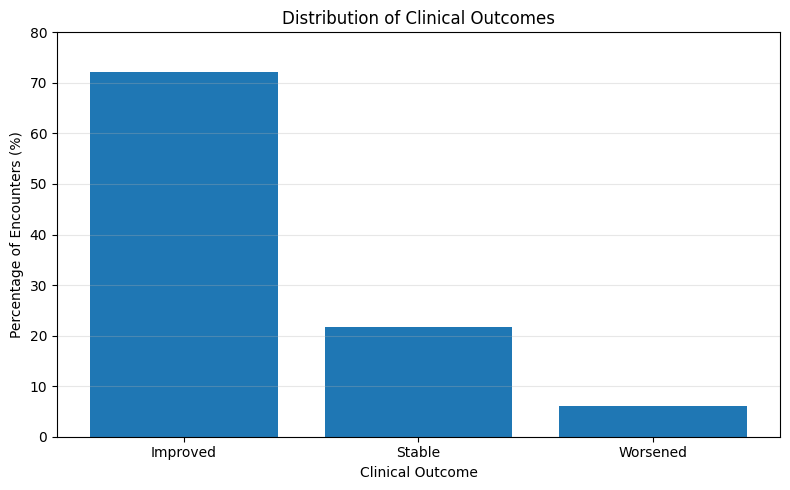

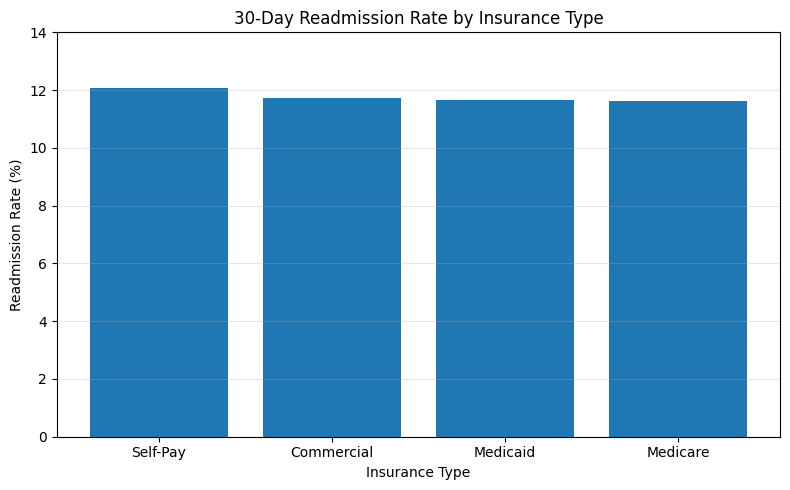

In [4]:
# Healthcare Analytics: Visualizing Key Findings

# Chart 1: Clinical outcome distribution
plt.figure(figsize=(8, 5))

plt.bar(
    outcome_summary["Outcome"],
    outcome_summary["Percentage (%)"]
)

plt.title("Distribution of Clinical Outcomes")
plt.xlabel("Clinical Outcome")
plt.ylabel("Percentage of Encounters (%)")
plt.ylim(0, 80)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Chart 2: Readmission rate by insurance type
readmission_chart = readmission_by_insurance.sort_values(
    "Readmission Rate (%)",
    ascending=False
)

plt.figure(figsize=(8, 5))

plt.bar(
    readmission_chart["Insurance Type"],
    readmission_chart["Readmission Rate (%)"]
)

plt.title("30-Day Readmission Rate by Insurance Type")
plt.xlabel("Insurance Type")
plt.ylabel("Readmission Rate (%)")
plt.ylim(0, 14)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Key Findings and Business Insights

## 1. Data Quality

- The dataset contains 100,000 healthcare encounters and 15 columns.
- No duplicate encounter IDs were identified.
- 250 records have missing provider assignments.
- 15 records have missing encounter dates.
- 900 patient satisfaction scores are missing.
- 40 records contain negative total costs that require financial validation.

These records were retained for investigation rather than automatically deleted or modified.

## 2. Clinical Outcomes

- **72.12%** of encounters had an outcome classified as Improved.
- **21.78%** were classified as Stable.
- **6.09%** were classified as Worsened.

The outcome distribution is predominantly positive, although the underlying clinical definitions and patient context would need to be reviewed before drawing conclusions about quality of care.

## 3. Thirty-Day Readmissions

- The overall 30-day readmission rate was **11.72%**.
- Self-Pay had the highest observed rate (**12.08%**).
- Medicare had the lowest observed rate (**11.62%**).

These differences are descriptive and do not establish that insurance type causes readmissions. Further analysis would be needed to account for patient characteristics, diagnoses, and other relevant factors.

## 4. Recommended Next Steps

1. Investigate the records with negative total costs and validate their financial meaning.
2. Determine how missing provider assignments and dates should be handled in reporting.
3. Examine readmissions by diagnosis and region.
4. Validate data definitions and investigate potential factors associated with clinical outcomes.

## Conclusion

This analysis demonstrates how Python can be used to inspect healthcare data, identify quality issues, calculate operational indicators, and communicate findings through visualizations. The results provide a foundation for further analysis in the healthcare data warehouse and Power BI dashboards.

In [5]:
# Final Data Quality Validation

quality_checks = {
    "Total records": len(df),
    "Total columns": len(df.columns),
    "Duplicate encounter IDs": df["encounter_id"].duplicated().sum(),
    "Missing provider IDs": df["provider_id"].isna().sum(),
    "Missing dates": df["date_id"].isna().sum(),
    "Missing patient satisfaction scores": df["patient_satisfaction"].isna().sum(),
    "Negative total costs": (df["total_cost"] < 0).sum(),
    "Missing clinical outcomes": df["outcome"].isna().sum()
}

quality_summary = pd.DataFrame(
    list(quality_checks.items()),
    columns=["Validation Check", "Result"]
)

display(quality_summary)

print(f"30-day readmission rate: {df['readmission_30_days'].mean():.2%}")
print(
    "Improved outcome rate: "
    f"{df['outcome'].eq('Improved').mean():.2%}"
)

,Validation Check,Result
0,Total records,100000
1,Total columns,15
2,Duplicate encounter IDs,0
3,Missing provider IDs,250
4,Missing dates,15
5,Missing patient satisfaction scores,900
6,Negative total costs,40
7,Missing clinical outcomes,0


30-day readmission rate: 11.72%
Improved outcome rate: 72.12%
